# Лабораторная работа 3. Калий между фиксированными углеродными стенками

**Цель:** изучить влияние четырёх непроницаемых в рамках модели стенок из неподвижных атомов углерода на траектории атомов калия и механическое давление на границы.

**Система:** 1035 частиц K в коробке $24\times24$ нм; все четыре границы представлены атомными рядами C; газ и стенки взаимодействуют потенциалом LJTS.

**Ожидаемый результат:** график движения K относительно C-стенок и временные зависимости энергий, температуры и силы на стенки на единицу длины.

**Студент:** ____________________  **Группа:** __________  **Преподаватель:** ____________________

> В DEMO сохраняется число частиц, но используется короткая траектория. FULL соответствует демонстрационным параметрам эксперимента task3 (2000 шагов). Измените `MODE` в первой ячейке, чтобы выбрать режим.

## 1. Постановка и теория стенок

Вместо периодического повторения области здесь задаются четыре ряда атомов углерода, закреплённых в пространстве. Частицы K взаимодействуют как друг с другом (K–K), так и с C-атомами (K–C); за пределами стенки дополнительных периодических копий нет. Если K приближается к стенке, отталкивающая часть потенциала разворачивает траекторию; более слабый притягивающий вклад может удерживать частицы рядом с поверхностью.

Геометрия — одномерный ряд атомов на каждой стороне 2D-прямоугольника. Расстояние вдоль алмазной поверхности принято равным $a/\sqrt2$, где параметр решётки алмаза $a=0.3567$ нм. Углы представлены один раз, чтобы не удваивать угловые атомы. Это двумерное сечение поверхности, не объёмный алмазный кристалл.

Для K–C применены правила Lorentz–Berthelot: $\sigma_{KC}=(\sigma_K+\sigma_C)/2$, $\varepsilon_{KC}=\sqrt{\varepsilon_K\varepsilon_C}$. UFF для атома углерода типа C_3 задаёт минимум $x_C=3.851$ Å и глубину $D_C=0.105$ ккал/моль. В стандартном LJ параметр $\sigma$ задаёт нулевое пересечение, поэтому $\sigma_C=x_C/2^{1/6}$. Энергию на моль переводим в энергию на пару/частицу множителем $4184/N_A$ Дж на ккал/моль.

Реакция фиксированных стенок позволяет вычислить механическое давление: модуль суммарной компоненты силы газа на стенку, делённый на длину этой стороны. Для левой/правой стенок $P_x=|\sum F_x|/L_y$, для верхней/нижней $P_y=|\sum F_y|/L_x$, единица Н/м. Это прямее характеризует контакт со стенкой, чем периодическая формула bulk-вириала. Энергия стенка–стенка не включается: координаты стенок постоянны, поэтому её изменение на динамику газа не влияет.

| Величина | Значение | Единица | Основание |
|---|---:|---|---|
| Частицы K | 1035 | атомов | Вариант 7 задания, из 4 моль/л |
| Температура | 1173.15 | K | 900 °C + 273.15 |
| Коробка | 24 × 24 | нм | Вариант 7 |
| $\sigma_K$, $\varepsilon_K/k_B$ | 0.4250; 850 | нм; K | Зафиксированные параметры кода, точный источник пары не найден |
| $x_C$, $D_C$ UFF | 3.851; 0.105 | Å; kcal/mol | Rappé et al., UFF, JACS 114 (1992), DOI [10.1021/ja00051a040](https://doi.org/10.1021/ja00051a040) |
| $a$, межрядное расстояние | 0.3567; 0.2522 | нм | Алмазная решётка; справочно [Argonne lattice constants](https://7id.xray.aps.anl.gov/calculators/crystal_lattice_parameters.html) |
| $\Delta t$, cutoff | 1 фс; $2.5\sigma$ | с; нм | Настройка модели |

Подвижные стенки, упругие моды, химическая связь и электронная проводимость не моделируются. Поэтому это исследование взаимодействия с эффективной фиксированной поверхностью, а не полноценная модель твёрдого тела.

## 2. Настройка кода

`MDEngine` — класс, который собирает конфигурацию, частицы, потенциалы и силы в одном объекте. `engine = MDEngine(config)` создаёт объект-состояние; `engine.step()` вызывает один шаг Velocity Verlet и возвращает словарь стандартных наблюдений. Силы реакции на каждую фиксированную стенку доступны в `engine.state.wall_reaction`; координаты атомов C лежат в `engine.wall_positions`. Здесь нужен собственный небольшой цикл, чтобы явно показать расчёт механического давления по каждой стороне: функция `run_nve` не возвращает раздельные силы стенок.

### Вычислительное ядро внутри notebook

Ниже приведён весь код, необходимый для расчёта. Блоки расположены в порядке зависимостей: от физических параметров к силам и интегратору. Каждый блок можно читать, изменять и выполнять как обычную Python-ячейку; скрытой загрузки кода нет.

In [ ]:
from pathlib import Path

# В Colab это /content; локально — каталог, из которого открыт notebook.
PROJECT_ROOT = Path.cwd()
print(f'Рабочий каталог: {PROJECT_ROOT}; результаты будут сохранены в output/')

#### Физические константы и параметры взаимодействия

Задаём единицы СИ, массу атома калия и параметры потенциалов K–K и K–C. Все энергии относятся к одной взаимодействующей паре, а не к молю.

In [ ]:
"""Physical constants and the fixed material parameters of the model.

The simulation core uses SI units. Energies are per particle, not per mole.
"""

from __future__ import annotations

from dataclasses import dataclass
import math


AVOGADRO = 6.022_140_76e23  # 1/mol, exact
BOLTZMANN = 1.380_649e-23  # J/K, exact
ATOMIC_MASS_UNIT = 1.660_539_066_60e-27  # kg

KELVIN_OFFSET_CELSIUS = 273.15
TEMPERATURE_C = 900.0
TEMPERATURE_K = TEMPERATURE_C + KELVIN_OFFSET_CELSIUS

MASS_K = 39.0983 * ATOMIC_MASS_UNIT
SIGMA_K = 0.4250e-9  # m
EPSILON_K = 850.0 * BOLTZMANN  # J/particle

# UFF C_3 values are used only for the fixed diamond wall. UFF lists the
# minimum position x and well depth D; sigma=x/2**(1/6) maps that minimum to
# the conventional 12-6 LJ form used by this project.
SIGMA_C = (3.851e-10) / (2.0 ** (1.0 / 6.0))
EPSILON_C = 0.105 * 4184.0 / AVOGADRO  # 0.105 kcal/mol -> J/particle
SIGMA_KC = 0.5 * (SIGMA_K + SIGMA_C)
EPSILON_KC = math.sqrt(EPSILON_K * EPSILON_C)
DIAMOND_LATTICE_CONSTANT = 0.3567e-9  # m
WALL_SPACING = DIAMOND_LATTICE_CONSTANT / math.sqrt(2.0)

LAYER_THICKNESS = (1.0e-3 / (4.0 * AVOGADRO)) ** (1.0 / 3.0)


@dataclass(frozen=True)
class LJParameters:
    sigma: float
    epsilon: float

    def __post_init__(self) -> None:
        if self.sigma <= 0.0 or self.epsilon <= 0.0:
            raise ValueError("LJ sigma and epsilon must be positive")

    @property
    def r_min(self) -> float:
        return 2.0 ** (1.0 / 6.0) * self.sigma

    @property
    def timescale(self) -> float:
        return self.sigma * math.sqrt(MASS_K / self.epsilon)


K_LJ = LJParameters(SIGMA_K, EPSILON_K)
C_LJ = LJParameters(SIGMA_C, EPSILON_C)
KC_LJ = LJParameters(SIGMA_KC, EPSILON_KC)


#### Геометрия и параметры расчёта

Собираем размер области, шаг интегрирования, число частиц, граничные условия и диагностические допуски в одну проверяемую конфигурацию.

In [ ]:
"""Configuration objects for the 2D MD engine."""

from __future__ import annotations

from dataclasses import dataclass, field
import math



@dataclass(frozen=True)
class Box:
    lx: float = 24.0e-9
    ly: float = 24.0e-9

    @property
    def area(self) -> float:
        return self.lx * self.ly


@dataclass(frozen=True)
class MDConfig:
    n_particles: int = 1035
    temperature: float = TEMPERATURE_K
    mass: float = MASS_K
    box: Box = field(default_factory=Box)
    lj: object = K_LJ
    cutoff_factor: float = 2.5
    dt: float = 1.0e-15
    periodic_x: bool = True
    periodic_y: bool = True
    remove_com: bool = True
    seed: int = 7
    force_backend: str = "bruteforce"
    wall_mode: str = "none"
    max_force_factor: float = 1.0e6
    max_relative_energy_drift: float = 5.0e-3

    @property
    def cutoff(self) -> float:
        return self.cutoff_factor * self.lj.sigma

    @property
    def degrees_of_freedom(self) -> int:
        removed = 2 if self.remove_com else 0
        return 2 * self.n_particles - removed

    def validate(self) -> None:
        if self.n_particles < 2:
            raise ValueError("At least two particles are required")
        if self.temperature <= 0.0 or self.mass <= 0.0 or self.dt <= 0.0:
            raise ValueError("temperature, mass, and dt must be positive")
        if self.cutoff_factor <= 0.0:
            raise ValueError("cutoff_factor must be positive")
        if self.periodic_x and self.cutoff >= self.box.lx / 2.0:
            raise ValueError("cutoff must be smaller than half the periodic x box")
        if self.periodic_y and self.cutoff >= self.box.ly / 2.0:
            raise ValueError("cutoff must be smaller than half the periodic y box")
        if self.degrees_of_freedom <= 0:
            raise ValueError("number of thermal degrees of freedom must be positive")
        if self.force_backend not in {"bruteforce", "cell_list"}:
            raise ValueError("force_backend must be 'bruteforce' or 'cell_list'")
        if self.wall_mode not in {"none", "all", "x"}:
            raise ValueError("wall_mode must be 'none', 'all', or 'x'")
        if self.wall_mode == "all" and (self.periodic_x or self.periodic_y):
            raise ValueError("all fixed walls require non-periodic x and y")
        if self.wall_mode == "x" and (self.periodic_x is True or self.periodic_y is False):
            raise ValueError("x-wall geometry requires x fixed and y periodic")
        if self.max_force_factor <= 0.0 or self.max_relative_energy_drift <= 0.0:
            raise ValueError("numerical safety thresholds must be positive")


def default_config(**overrides: object) -> MDConfig:
    values = {name: getattr(MDConfig(), name) for name in MDConfig.__dataclass_fields__}
    values.update(overrides)
    config = MDConfig(**values)
    config.validate()
    return config


#### Граничные условия

Реализуем периодическое заворачивание координат, minimum-image расстояние и отражение от непериодических границ.

In [ ]:
"""Boundary and minimum-image operations for rectangular 2D boxes."""

from __future__ import annotations

import numpy as np



def minimum_image(
    displacement: np.ndarray,
    box: Box,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> np.ndarray:
    result = np.asarray(displacement, dtype=np.float64).copy()
    if periodic_x:
        result[..., 0] -= box.lx * np.round(result[..., 0] / box.lx)
    if periodic_y:
        result[..., 1] -= box.ly * np.round(result[..., 1] / box.ly)
    return result


def wrap_positions(
    positions: np.ndarray,
    box: Box,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> np.ndarray:
    wrapped = np.asarray(positions, dtype=np.float64).copy()
    if periodic_x:
        wrapped[:, 0] %= box.lx
    if periodic_y:
        wrapped[:, 1] %= box.ly
    return wrapped


def validate_positions_in_box(
    positions: np.ndarray,
    box: Box,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> None:
    """Reject crossing of a fixed boundary instead of silently clipping it."""
    values = np.asarray(positions)
    if not np.all(np.isfinite(values)):
        raise FloatingPointError("non-finite coordinates after integration")
    tolerance = 1.0e-15
    if not periodic_x and (
        np.any(values[:, 0] < -tolerance) or np.any(values[:, 0] > box.lx + tolerance)
    ):
        raise FloatingPointError("particle crossed fixed x boundary")
    if not periodic_y and (
        np.any(values[:, 1] < -tolerance) or np.any(values[:, 1] > box.ly + tolerance)
    ):
        raise FloatingPointError("particle crossed fixed y boundary")


#### Парный потенциал Леннарда — Джонса

Вычисляем энергию и производную LJ, затем обрезаем и сдвигаем энергию на радиусе cutoff. Проверка отдельно останавливает численно опасные сближения.

In [ ]:
"""Analytic Lennard-Jones and truncated-shifted Lennard-Jones functions."""

from __future__ import annotations

from dataclasses import dataclass
import numpy as np



class NumericalInstabilityError(RuntimeError):
    """Raised when a pair distance is too small for a stable LJ evaluation."""


@dataclass(frozen=True)
class LJTS:
    parameters: LJParameters
    cutoff: float
    minimum_distance: float = 1.0e-15

    def __post_init__(self) -> None:
        if self.cutoff <= 0.0:
            raise ValueError("cutoff must be positive")
        if self.minimum_distance <= 0.0:
            raise ValueError("minimum_distance must be positive")

    def energy_and_radial_derivative(self, distance: float) -> tuple[float, float]:
        if not np.isfinite(distance) or distance < self.minimum_distance:
            raise NumericalInstabilityError(
                f"invalid pair distance r={distance:.6e} m"
            )
        if distance >= self.cutoff:
            return 0.0, 0.0

        u_lj, derivative = lj_energy_and_radial_derivative(distance, self.parameters)
        u_cut, _ = lj_energy_and_radial_derivative(self.cutoff, self.parameters)
        return u_lj - u_cut, derivative

    def force_on_i(self, displacement_i_from_j: np.ndarray) -> tuple[float, np.ndarray]:
        distance = float(np.linalg.norm(displacement_i_from_j))
        energy, derivative = self.energy_and_radial_derivative(distance)
        if derivative == 0.0:
            return energy, np.zeros(2, dtype=np.float64)
        # displacement is r_i-r_j; force is -grad_{r_i} U.
        force = -derivative * displacement_i_from_j / distance
        return energy, force


def lj_energy_and_radial_derivative(
    distance: float, parameters: LJParameters
) -> tuple[float, float]:
    """Return the unshifted LJ energy and dU/dr."""
    if not np.isfinite(distance) or distance <= 0.0:
        raise NumericalInstabilityError(f"invalid pair distance r={distance:.6e} m")
    sigma = parameters.sigma
    epsilon = parameters.epsilon
    sr6 = (sigma / distance) ** 6
    energy = 4.0 * epsilon * (sr6 * sr6 - sr6)
    derivative = 24.0 * epsilon / distance * (sr6 - 2.0 * sr6 * sr6)
    return energy, derivative


#### Начальные координаты и скорости

Частицы размещаются на слегка возмущённой решётке. Скорости выбираются из распределения Максвелла, затем удаляется движение центра масс и задаётся температура.

In [ ]:
"""Reproducible initial coordinates and Maxwell-Boltzmann velocities."""

from __future__ import annotations

import numpy as np



def _stream_rng(config: MDConfig, stream: int) -> np.random.Generator:
    """Create one deterministic, independent stream for a state component."""
    streams = np.random.SeedSequence(config.seed).spawn(2)
    return np.random.default_rng(streams[stream])


def lattice_positions(
    config: MDConfig,
    jitter_fraction: float = 0.08,
    rng: np.random.Generator | None = None,
) -> np.ndarray:
    """Place particles on a near-uniform 2D lattice with reproducible jitter."""
    if not 0.0 <= jitter_fraction < 0.25:
        raise ValueError("jitter_fraction must be in [0, 0.25)")

    margin = 0.0
    if config.wall_mode in {"all", "x"}:
        margin = 0.75 * KC_LJ.r_min
    if config.wall_mode == "all":
        lower = np.array([margin, margin])
        upper = np.array([config.box.lx - margin, config.box.ly - margin])
    elif config.wall_mode == "x":
        lower = np.array([margin, 0.0])
        upper = np.array([config.box.lx - margin, config.box.ly])
    else:
        lower = np.zeros(2)
        upper = np.array([config.box.lx, config.box.ly])
    available = upper - lower
    n_x = int(np.ceil(np.sqrt(config.n_particles * available[0] / available[1])))
    n_y = int(np.ceil(config.n_particles / n_x))
    spacing_x = available[0] / n_x
    spacing_y = available[1] / n_y
    capacity = n_x * n_y
    # Evenly sample the flattened lattice instead of taking a contiguous
    # prefix, which would leave a visibly underfilled final row.
    selected = np.floor(
        (np.arange(config.n_particles, dtype=np.float64) + 0.5)
        * capacity
        / config.n_particles
    ).astype(np.intp)
    ix = selected % n_x
    iy = selected // n_x
    positions = np.column_stack(
        (lower[0] + (ix + 0.5) * spacing_x, lower[1] + (iy + 0.5) * spacing_y)
    ).astype(np.float64)

    if jitter_fraction:
        rng = _stream_rng(config, 0) if rng is None else rng
        jitter = rng.uniform(-jitter_fraction, jitter_fraction, positions.shape)
        positions[:, 0] += jitter[:, 0] * spacing_x
        positions[:, 1] += jitter[:, 1] * spacing_y
    return positions


def maxwell_boltzmann_velocities(
    config: MDConfig,
    rng: np.random.Generator | None = None,
) -> np.ndarray:
    """Generate 2D velocities, remove COM motion, and rescale to target T."""
    rng = _stream_rng(config, 1) if rng is None else rng
    scale = np.sqrt(BOLTZMANN * config.temperature / config.mass)
    velocities = rng.normal(0.0, scale, size=(config.n_particles, 2))
    if config.remove_com:
        velocities -= velocities.mean(axis=0)

    kinetic = 0.5 * config.mass * np.sum(velocities * velocities)
    measured = 2.0 * kinetic / (config.degrees_of_freedom * BOLTZMANN)
    if not np.isfinite(measured) or measured <= 0.0:
        raise FloatingPointError("invalid initial kinetic temperature")
    velocities *= np.sqrt(config.temperature / measured)
    return velocities


def initialize(config: MDConfig) -> tuple[np.ndarray, np.ndarray]:
    config.validate()
    position_seed, velocity_seed = np.random.SeedSequence(config.seed).spawn(2)
    return lattice_positions(
        config, rng=np.random.default_rng(position_seed)
    ), maxwell_boltzmann_velocities(
        config, rng=np.random.default_rng(velocity_seed)
    )


#### Измеряемые физические величины

Определяем кинетическую энергию, мгновенную температуру, двумерное вириальное давление и механическое давление на x-стенки.

In [ ]:
"""Thermodynamic observables for a 2D system."""

from __future__ import annotations

import numpy as np



def kinetic_energy(velocities: np.ndarray, mass: float) -> float:
    return float(0.5 * mass * np.sum(np.asarray(velocities) ** 2))


def instantaneous_temperature(
    velocities: np.ndarray,
    mass: float,
    remove_com: bool = True,
) -> float:
    values = np.asarray(velocities, dtype=np.float64)
    if remove_com:
        values = values - values.mean(axis=0)
    dof = 2 * len(values) - (2 if remove_com else 0)
    return 2.0 * kinetic_energy(values, mass) / (dof * BOLTZMANN)


def pressure_2d(kinetic: float, virial: float, area: float) -> float:
    return (kinetic + 0.5 * virial) / area


def pressure_on_x_walls(
    wall_positions: np.ndarray,
    wall_reaction: np.ndarray,
    box_length_y: float,
) -> tuple[float, float, float]:
    """Return left, right, and mean mechanical pressure in N/m."""
    tolerance = max(1.0e-15, box_length_y * 1.0e-12)
    left = np.isclose(wall_positions[:, 0], 0.0, atol=tolerance)
    right = np.isclose(
        wall_positions[:, 0], np.max(wall_positions[:, 0]), atol=tolerance
    )
    left_pressure = abs(float(np.sum(wall_reaction[left, 0]))) / box_length_y
    right_pressure = abs(float(np.sum(wall_reaction[right, 0]))) / box_length_y
    return left_pressure, right_pressure, 0.5 * (left_pressure + right_pressure)


#### Геометрия углеродных стенок

Строим фиксированные ряды атомов углерода с шагом алмазной решётки. Эти атомы создают внешнее поле, но сами не интегрируются во времени.

In [ ]:
"""Fixed one-layer diamond-carbon wall geometry."""

from __future__ import annotations

import numpy as np



def _line_positions(length: float) -> np.ndarray:
    count = max(2, int(np.floor(length / WALL_SPACING)) + 1)
    return np.linspace(0.0, length, count, dtype=np.float64)


def _periodic_line_positions(length: float) -> np.ndarray:
    count = max(1, int(np.floor(length / WALL_SPACING)))
    return np.arange(count, dtype=np.float64) * (length / count)


def diamond_wall_positions(box: Box, mode: str) -> np.ndarray:
    """Return one fixed C-atom line per required side.

    In this strictly 2D representation, (100) diamond surface order is
    represented by the in-plane spacing a/sqrt(2). Corner atoms are unique.
    """
    if mode not in {"all", "x"}:
        raise ValueError("wall mode must be 'all' or 'x'")
    atoms: set[tuple[float, float]] = set()
    y_values = _periodic_line_positions(box.ly) if mode == "x" else _line_positions(box.ly)
    x_values = _line_positions(box.lx)
    for y in y_values:
        atoms.add((0.0, float(y)))
        atoms.add((box.lx, float(y)))
    if mode == "all":
        for x in x_values:
            atoms.add((float(x), 0.0))
            atoms.add((float(x), box.ly))
    return np.asarray(sorted(atoms), dtype=np.float64)


#### Расчёт межатомных сил

Суммируем парные силы, потенциальную энергию и вириал. Для больших систем используется список пространственных ячеек; поддерживается и взаимодействие со стенками.

In [ ]:
"""Reference O(N^2) pair-force calculation."""

from __future__ import annotations

import numpy as np



def compute_forces_bruteforce(
    positions: np.ndarray,
    box: Box,
    potential: LJTS,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> tuple[np.ndarray, float, float]:
    """Return forces, potential energy, and positive-repulsion virial.

    ``displacement = r_i-r_j`` and the returned pair force is force on i
    from j. The stored virial is ``sum(displacement dot force_i)`` so that
    the 2D pressure is ``(kinetic_energy + virial / 2) / area``.
    """
    coordinates = np.asarray(positions, dtype=np.float64)
    if coordinates.ndim != 2 or coordinates.shape[1] != 2:
        raise ValueError("positions must have shape (N, 2)")
    if not np.all(np.isfinite(coordinates)):
        raise FloatingPointError("non-finite coordinates")

    forces = np.zeros_like(coordinates)
    potential_energy = 0.0
    virial = 0.0
    for i in range(len(coordinates) - 1):
        for j in range(i + 1, len(coordinates)):
            displacement = minimum_image(
                coordinates[i] - coordinates[j],
                box,
                periodic_x=periodic_x,
                periodic_y=periodic_y,
            )
            energy, force_i = potential.force_on_i(displacement)
            forces[i] += force_i
            forces[j] -= force_i
            potential_energy += energy
            virial += float(np.dot(displacement, force_i))

    if not np.all(np.isfinite(forces)) or not np.isfinite(potential_energy):
        raise FloatingPointError("non-finite force or potential energy")
    return forces, potential_energy, virial


def compute_forces_cell_list(
    positions: np.ndarray,
    box: Box,
    potential: LJTS,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> tuple[np.ndarray, float, float]:
    """Cell-list version of the pair calculation.

    The cell width is chosen not smaller than the cutoff, so the 3x3
    neighboring-cell stencil is sufficient. Pair arithmetic is intentionally
    identical to the reference backend.
    """
    coordinates = np.asarray(positions, dtype=np.float64)
    if coordinates.ndim != 2 or coordinates.shape[1] != 2:
        raise ValueError("positions must have shape (N, 2)")
    if not np.all(np.isfinite(coordinates)):
        raise FloatingPointError("non-finite coordinates")

    lengths = np.array([box.lx, box.ly], dtype=np.float64)
    periodic = (periodic_x, periodic_y)
    n_cells = np.maximum(1, np.floor(lengths / potential.cutoff).astype(int))
    cell_width = lengths / n_cells
    cell_of_particle = np.floor(coordinates / cell_width).astype(int)
    for axis in range(2):
        cell_of_particle[:, axis] = np.clip(
            cell_of_particle[:, axis], 0, n_cells[axis] - 1
        )

    cells: dict[tuple[int, int], list[int]] = {}
    for particle, cell in enumerate(cell_of_particle):
        key = (int(cell[0]), int(cell[1]))
        cells.setdefault(key, []).append(particle)

    pair_i: list[int] = []
    pair_j: list[int] = []
    for i, cell in enumerate(cell_of_particle):
        neighbor_keys: set[tuple[int, int]] = set()
        for dx in (-1, 0, 1):
            for dy in (-1, 0, 1):
                candidate = [int(cell[0] + dx), int(cell[1] + dy)]
                valid = True
                for axis, is_periodic in enumerate(periodic):
                    if is_periodic:
                        candidate[axis] %= int(n_cells[axis])
                    elif not 0 <= candidate[axis] < n_cells[axis]:
                        valid = False
                if valid:
                    neighbor_keys.add((candidate[0], candidate[1]))

        for key in neighbor_keys:
            for j in cells.get(key, ()):
                if j <= i:
                    continue
                pair_i.append(i)
                pair_j.append(j)

    forces = np.zeros_like(coordinates)
    if pair_i:
        indices_i = np.asarray(pair_i, dtype=np.intp)
        indices_j = np.asarray(pair_j, dtype=np.intp)
        displacements = minimum_image(
            coordinates[indices_i] - coordinates[indices_j],
            box,
            periodic_x=periodic_x,
            periodic_y=periodic_y,
        )
        distances = np.linalg.norm(displacements, axis=1)
        active = distances < potential.cutoff
        if np.any(distances[active] < potential.minimum_distance):
            bad_distance = float(np.min(distances[active]))
            raise FloatingPointError(f"invalid pair distance r={bad_distance:.6e} m")
        if np.any(active):
            active_i = indices_i[active]
            active_j = indices_j[active]
            active_displacements = displacements[active]
            active_distances = distances[active]
            sigma = potential.parameters.sigma
            epsilon = potential.parameters.epsilon
            sr6 = (sigma / active_distances) ** 6
            sr6_cut = (sigma / potential.cutoff) ** 6
            u_cut = 4.0 * epsilon * (sr6_cut * sr6_cut - sr6_cut)
            pair_energy = 4.0 * epsilon * (sr6 * sr6 - sr6) - u_cut
            derivative = 24.0 * epsilon / active_distances * (sr6 - 2.0 * sr6 * sr6)
            pair_forces = -derivative[:, None] * active_displacements / active_distances[:, None]
            np.add.at(forces, active_i, pair_forces)
            np.add.at(forces, active_j, -pair_forces)
            potential_energy = float(np.sum(pair_energy))
            virial = float(np.sum(np.einsum("ij,ij->i", active_displacements, pair_forces)))
        else:
            potential_energy = 0.0
            virial = 0.0
    else:
        potential_energy = 0.0
        virial = 0.0

    if not np.all(np.isfinite(forces)) or not np.isfinite(potential_energy):
        raise FloatingPointError("non-finite force or potential energy")
    return forces, potential_energy, virial


def compute_forces(
    positions: np.ndarray,
    box: Box,
    potential: LJTS,
    periodic_x: bool = True,
    periodic_y: bool = True,
    backend: str = "bruteforce",
) -> tuple[np.ndarray, float, float]:
    if backend == "bruteforce":
        return compute_forces_bruteforce(
            positions, box, potential, periodic_x, periodic_y
        )
    if backend == "cell_list":
        return compute_forces_cell_list(
            positions, box, potential, periodic_x, periodic_y
        )
    raise ValueError(f"unknown force backend: {backend}")


def compute_forces_with_walls(
    positions: np.ndarray,
    box: Box,
    gas_potential: LJTS,
    wall_positions: np.ndarray,
    wall_potential: LJTS,
    periodic_x: bool,
    periodic_y: bool,
    backend: str = "cell_list",
) -> tuple[np.ndarray, float, float, np.ndarray]:
    """Gas-gas plus gas-fixed-wall interactions.

    ``wall_reaction`` is the force exerted by gas on each fixed wall atom.
    Wall-wall energy is omitted because fixed wall coordinates make it a
    constant irrelevant to gas dynamics.
    """
    gas_forces, gas_energy, gas_virial = compute_forces(
        positions,
        box,
        gas_potential,
        periodic_x,
        periodic_y,
        backend,
    )
    walls = np.asarray(wall_positions, dtype=np.float64)
    displacement = np.asarray(positions)[:, None, :] - walls[None, :, :]
    displacement = minimum_image(
        displacement, box, periodic_x=periodic_x, periodic_y=periodic_y
    )
    distances = np.linalg.norm(displacement, axis=2)
    active = distances < wall_potential.cutoff
    if np.any(distances[active] < wall_potential.minimum_distance):
        raise FloatingPointError("K atom overlaps a fixed carbon wall atom")

    pair_forces = np.zeros_like(displacement)
    pair_energy = 0.0
    wall_virial = 0.0
    if np.any(active):
        active_distances = distances[active]
        sigma = wall_potential.parameters.sigma
        epsilon = wall_potential.parameters.epsilon
        sr6 = (sigma / active_distances) ** 6
        sr6_cut = (sigma / wall_potential.cutoff) ** 6
        u_cut = 4.0 * epsilon * (sr6_cut * sr6_cut - sr6_cut)
        pair_energy = float(np.sum(4.0 * epsilon * (sr6 * sr6 - sr6) - u_cut))
        derivative = 24.0 * epsilon / active_distances * (sr6 - 2.0 * sr6 * sr6)
        pair_forces[active] = -derivative[:, None] * displacement[active] / active_distances[:, None]
        wall_virial = float(np.sum(displacement[active] * pair_forces[active]))

    gas_forces += np.sum(pair_forces, axis=1)
    wall_reaction = -np.sum(pair_forces, axis=0)
    total_energy = gas_energy + pair_energy
    total_virial = gas_virial + wall_virial
    if not np.all(np.isfinite(gas_forces)) or not np.isfinite(total_energy):
        raise FloatingPointError("non-finite wall force or energy")
    return gas_forces, total_energy, total_virial, wall_reaction


#### Интегрирование уравнений движения

Один шаг velocity Verlet последовательно обновляет координаты, силы и скорости. Есть варианты для периодической системы и системы с фиксированными стенками.

In [ ]:
"""Time integration schemes."""

from __future__ import annotations

import numpy as np



def velocity_verlet_step(
    positions: np.ndarray,
    velocities: np.ndarray,
    forces: np.ndarray,
    config: MDConfig,
    potential: LJTS,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, float, float]:
    """Advance one NVE step and return new state plus U and virial."""
    acceleration = forces / config.mass
    new_positions = (
        positions + velocities * config.dt + 0.5 * acceleration * config.dt**2
    )
    new_positions = wrap_positions(
        new_positions,
        config.box,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
    )
    validate_positions_in_box(
        new_positions, config.box, config.periodic_x, config.periodic_y
    )
    new_forces, potential_energy, virial = compute_forces(
        new_positions,
        config.box,
        potential,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
        backend=config.force_backend,
    )
    new_acceleration = new_forces / config.mass
    new_velocities = velocities + 0.5 * (acceleration + new_acceleration) * config.dt
    return new_positions, new_velocities, new_forces, potential_energy, virial


def velocity_verlet_step_with_walls(
    positions: np.ndarray,
    velocities: np.ndarray,
    forces: np.ndarray,
    config: MDConfig,
    gas_potential: LJTS,
    wall_positions: np.ndarray,
    wall_potential: LJTS,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, float, float, np.ndarray]:
    """Velocity Verlet for mobile K atoms in a fixed external wall field."""
    acceleration = forces / config.mass
    new_positions = positions + velocities * config.dt + 0.5 * acceleration * config.dt**2
    new_positions = wrap_positions(
        new_positions,
        config.box,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
    )
    validate_positions_in_box(
        new_positions, config.box, config.periodic_x, config.periodic_y
    )
    new_forces, potential_energy, virial, wall_reaction = compute_forces_with_walls(
        new_positions,
        config.box,
        gas_potential,
        wall_positions,
        wall_potential,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
        backend=config.force_backend,
    )
    new_acceleration = new_forces / config.mass
    new_velocities = velocities + 0.5 * (acceleration + new_acceleration) * config.dt
    return (
        new_positions,
        new_velocities,
        new_forces,
        potential_energy,
        virial,
        wall_reaction,
    )


#### Движок молекулярной динамики

Объединяем инициализацию, силы, интегратор и наблюдаемые величины. `MDEngine` выполняет шаги, а `run_nve` сохраняет временные ряды и кадры траектории.

In [ ]:
"""Small reference MD engine used by the tests and later experiments."""

from __future__ import annotations

from dataclasses import dataclass
import numpy as np



@dataclass
class MDState:
    positions: np.ndarray
    velocities: np.ndarray
    forces: np.ndarray
    potential_energy: float
    virial: float
    wall_reaction: np.ndarray | None = None
    step: int = 0

    @property
    def kinetic_energy(self) -> float:
        raise AttributeError("kinetic energy requires the engine mass")


class MDEngine:
    def __init__(self, config: MDConfig, positions: np.ndarray | None = None, velocities: np.ndarray | None = None):
        config.validate()
        self.config = config
        self.potential = LJTS(config.lj, config.cutoff)
        self.wall_positions = (
            diamond_wall_positions(config.box, config.wall_mode)
            if config.wall_mode != "none"
            else None
        )
        self.wall_potential = (
            LJTS(KC_LJ, 2.5 * KC_LJ.sigma)
            if self.wall_positions is not None
            else None
        )
        if positions is None or velocities is None:
            positions, velocities = initialize(config)
        self.state = self._make_state(positions, velocities)

    def _make_state(self, positions: np.ndarray, velocities: np.ndarray) -> MDState:
        if self.wall_positions is None:
            forces, energy, virial = compute_forces(
                positions,
                self.config.box,
                self.potential,
                periodic_x=self.config.periodic_x,
                periodic_y=self.config.periodic_y,
                backend=self.config.force_backend,
            )
            wall_reaction = None
        else:
            forces, energy, virial, wall_reaction = compute_forces_with_walls(
                positions,
                self.config.box,
                self.potential,
                self.wall_positions,
                self.wall_potential,
                periodic_x=self.config.periodic_x,
                periodic_y=self.config.periodic_y,
                backend=self.config.force_backend,
            )
        state = MDState(
            np.asarray(positions, dtype=np.float64).copy(),
            np.asarray(velocities, dtype=np.float64).copy(),
            forces,
            energy,
            virial,
            wall_reaction,
        )
        self._validate_force_scale(state.forces)
        return state

    def _validate_force_scale(self, forces: np.ndarray) -> None:
        scale = self.config.lj.epsilon / self.config.lj.sigma
        if self.wall_potential is not None:
            scale = max(scale, self.wall_potential.parameters.epsilon / self.wall_potential.parameters.sigma)
        limit = self.config.max_force_factor * scale
        maximum = float(np.max(np.linalg.norm(forces, axis=1)))
        if not np.isfinite(maximum) or maximum > limit:
            raise NumericalInstabilityError(
                f"force magnitude {maximum:.6e} N exceeds diagnostic limit {limit:.6e} N"
            )

    def step(self) -> dict[str, float]:
        state = self.state
        if self.wall_positions is None:
            positions, velocities, forces, potential, virial = velocity_verlet_step(
                state.positions,
                state.velocities,
                state.forces,
                self.config,
                self.potential,
            )
            wall_reaction = None
        else:
            (
                positions,
                velocities,
                forces,
                potential,
                virial,
                wall_reaction,
            ) = velocity_verlet_step_with_walls(
                state.positions,
                state.velocities,
                state.forces,
                self.config,
                self.potential,
                self.wall_positions,
                self.wall_potential,
            )
        state.positions = positions
        state.velocities = velocities
        state.forces = forces
        state.potential_energy = potential
        state.virial = virial
        state.wall_reaction = wall_reaction
        state.step += 1
        self._validate_force_scale(forces)
        kinetic = kinetic_energy(velocities, self.config.mass)
        observation = {
            "step": float(state.step),
            "kinetic_energy": kinetic,
            "potential_energy": potential,
            "total_energy": kinetic + potential,
            "temperature": instantaneous_temperature(
                velocities, self.config.mass, self.config.remove_com
            ),
            "pressure_2d": pressure_2d(kinetic, virial, self.config.box.area),
        }
        if wall_reaction is not None and self.config.wall_mode == "x":
            _, _, wall_pressure = pressure_on_x_walls(
                self.wall_positions, wall_reaction, self.config.box.ly
            )
            observation["pressure_wall_x"] = wall_pressure
        return observation


def run_nve(
    config: MDConfig,
    n_steps: int,
    sample_interval: int = 1,
    frame_interval: int = 20,
) -> tuple[dict[str, np.ndarray], np.ndarray]:
    """Run NVE and return sampled observables plus wrapped coordinate frames."""
    if n_steps <= 0 or sample_interval <= 0 or frame_interval <= 0:
        raise ValueError("step and sampling intervals must be positive")
    engine = MDEngine(config)
    rows: list[dict[str, float]] = []
    frames: list[np.ndarray] = []

    def record(observation: dict[str, float]) -> None:
        rows.append(observation | {"time": observation["step"] * config.dt})
        frames.append(engine.state.positions.copy())

    initial_kinetic = kinetic_energy(engine.state.velocities, config.mass)
    reference_energy = initial_kinetic + engine.state.potential_energy
    initial_observation = {
        "step": 0.0,
        "kinetic_energy": initial_kinetic,
        "potential_energy": engine.state.potential_energy,
        "total_energy": initial_kinetic + engine.state.potential_energy,
        "temperature": instantaneous_temperature(
            engine.state.velocities, config.mass, config.remove_com
        ),
        "pressure_2d": pressure_2d(
            initial_kinetic, engine.state.virial, config.box.area
        ),
    }
    if config.wall_mode == "x":
        _, _, initial_observation["pressure_wall_x"] = pressure_on_x_walls(
            engine.wall_positions, engine.state.wall_reaction, config.box.ly
        )
    record(initial_observation)
    for step in range(1, n_steps + 1):
        observation = engine.step()
        relative_drift = abs(observation["total_energy"] - reference_energy) / max(
            abs(reference_energy), 1.0e-30
        )
        if relative_drift > config.max_relative_energy_drift:
            raise NumericalInstabilityError(
                f"relative NVE energy drift {relative_drift:.6e} exceeds "
                f"limit {config.max_relative_energy_drift:.6e}"
            )
        if step % sample_interval == 0:
            rows.append(observation | {"time": step * config.dt})
        if step % frame_interval == 0:
            frames.append(engine.state.positions.copy())

    history = {
        key: np.asarray([row[key] for row in rows], dtype=np.float64)
        for key in rows[0]
    }
    return history, np.asarray(frames, dtype=np.float64)


#### Графики и анимации

Функции Matplotlib строят диагностические графики и сохраняют GIF-анимации. Этот блок не участвует в вычислении сил.

In [ ]:
"""Matplotlib output for trajectories and observables."""

from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import numpy as np


J_TO_EV = 1.0 / 1.602_176_634e-19


def save_task1_plots(
    history: dict[str, np.ndarray],
    output_dir: Path,
    ideal_pressure_2d: float | None = None,
) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)
    time_ps = history["time"] * 1.0e12
    plots = [
        ("kinetic_energy", "Kinetic energy", "energy (10^-18 J)", 1.0e18),
        ("potential_energy", "Potential energy", "energy (10^-18 J)", 1.0e18),
        ("total_energy", "Total energy", "energy (10^-18 J)", 1.0e18),
        ("temperature", "Instantaneous temperature", "temperature (K)", 1.0),
        ("pressure_2d", "Instantaneous 2D pressure", "pressure (N/m)", 1.0),
    ]
    for key, title, ylabel, scale in plots:
        figure, axis = plt.subplots(figsize=(7, 4))
        axis.plot(time_ps, history[key] * scale, label=key.replace("_", " "))
        if key == "pressure_2d" and ideal_pressure_2d is not None:
            axis.axhline(
                ideal_pressure_2d,
                color="tab:red",
                linestyle="--",
                label="ideal-gas reference",
            )
        axis.set_title(title)
        axis.set_xlabel("time (ps)")
        axis.set_ylabel(ylabel)
        axis.legend()
        axis.grid(alpha=0.25)
        figure.tight_layout()
        figure.savefig(output_dir / f"{key}_vs_time.png", dpi=150)
        plt.close(figure)

    figure, axis = plt.subplots(figsize=(7, 4))
    for key, label in (
        ("total_energy", "total"),
        ("kinetic_energy", "kinetic"),
        ("potential_energy", "potential"),
    ):
        axis.plot(time_ps, history[key] * 1.0e18, label=label)
    axis.set_title("Energy components")
    axis.set_xlabel("time (ps)")
    axis.set_ylabel("energy (10^-18 J)")
    axis.legend()
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(output_dir / "energy_components_vs_time.png", dpi=150)
    plt.close(figure)

    initial_energy = history["total_energy"][0]
    relative_deviation = (
        history["total_energy"] - initial_energy
    ) / max(abs(initial_energy), 1.0e-30)
    figure, axis = plt.subplots(figsize=(7, 4))
    axis.plot(time_ps, relative_deviation, label="(E-E0)/|E0|")
    axis.axhline(0.0, color="black", linewidth=0.8)
    axis.set_title("Relative total-energy deviation")
    axis.set_xlabel("time (ps)")
    axis.set_ylabel("relative energy deviation")
    axis.legend()
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(output_dir / "relative_energy_deviation_vs_time.png", dpi=150)
    plt.close(figure)


def save_task1_animation(
    frames: np.ndarray,
    box_length: float,
    output_path: Path,
    interval_ms: int = 40,
) -> None:
    if len(frames) == 0:
        raise ValueError("at least one frame is required")
    output_path.parent.mkdir(parents=True, exist_ok=True)
    figure, axis = plt.subplots(figsize=(6, 6))
    scatter = axis.scatter(frames[0, :, 0] * 1e9, frames[0, :, 1] * 1e9, s=8)
    axis.set_xlim(0.0, box_length * 1e9)
    axis.set_ylim(0.0, box_length * 1e9)
    axis.set_aspect("equal")
    axis.set_xlabel("x (nm)")
    axis.set_ylabel("y (nm)")
    axis.set_title("2D potassium gas: periodic NVE")

    def update(frame: np.ndarray):
        scatter.set_offsets(frame * 1e9)
        return (scatter,)

    animation = FuncAnimation(
        figure, update, frames=frames, interval=interval_ms, blit=True
    )
    animation.save(output_path, writer=PillowWriter(fps=max(1, 1000 // interval_ms)))
    plt.close(figure)


def save_equilibrium_pressure_plot(
    history: dict[str, np.ndarray],
    equilibration_index: int,
    equilibrium_mean: float,
    output_path: Path,
) -> None:
    output_path.parent.mkdir(parents=True, exist_ok=True)
    time_ps = history["time"] * 1e12
    pressure = history["pressure_2d"]
    figure, axis = plt.subplots(figsize=(8, 4.5))
    axis.plot(time_ps, pressure, lw=0.8, label="instantaneous P")
    axis.axvline(
        time_ps[equilibration_index],
        color="tab:red",
        ls="--",
        label="equilibration point",
    )
    axis.axhline(
        equilibrium_mean,
        color="tab:green",
        ls="-",
        label="equilibrium mean",
    )
    axis.set_title("Equilibrium pressure detection")
    axis.set_xlabel("time (ps)")
    axis.set_ylabel("2D pressure (N/m)")
    axis.legend()
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(output_path, dpi=150)
    plt.close(figure)


def save_wall_animation(
    frames: np.ndarray,
    wall_positions: np.ndarray,
    box_length_x: float,
    box_length_y: float,
    output_path: Path,
    interval_ms: int = 40,
) -> None:
    output_path.parent.mkdir(parents=True, exist_ok=True)
    figure, axis = plt.subplots(figsize=(6, 6))
    gas = axis.scatter(frames[0, :, 0] * 1e9, frames[0, :, 1] * 1e9, s=8, label="K")
    axis.scatter(
        wall_positions[:, 0] * 1e9,
        wall_positions[:, 1] * 1e9,
        s=16,
        color="black",
        label="fixed C wall",
    )
    axis.set_xlim(0.0, box_length_x * 1e9)
    axis.set_ylim(0.0, box_length_y * 1e9)
    axis.set_aspect("equal")
    axis.set_xlabel("x (nm)")
    axis.set_ylabel("y (nm)")
    axis.set_title("2D potassium gas with fixed carbon walls")
    axis.legend()

    def update(frame: np.ndarray):
        gas.set_offsets(frame * 1e9)
        return (gas,)

    animation = FuncAnimation(
        figure, update, frames=frames, interval=interval_ms, blit=True
    )
    animation.save(output_path, writer=PillowWriter(fps=max(1, 1000 // interval_ms)))
    plt.close(figure)


def save_phase_plot(
    temperatures: np.ndarray,
    mean_susceptibility: np.ndarray,
    transition_temperature: float,
    output_path: Path,
) -> None:
    output_path.parent.mkdir(parents=True, exist_ok=True)
    figure, axis = plt.subplots(figsize=(7, 4.5))
    axis.plot(temperatures, mean_susceptibility, "o-", label="cluster susceptibility")
    axis.axvline(
        transition_temperature,
        color="tab:red",
        ls="--",
        label=f"maximum: {transition_temperature:.1f} K",
    )
    axis.set_xlabel("temperature (K)")
    axis.set_ylabel("N Var(largest-cluster fraction)")
    axis.set_title("Finite-system gas-to-condensed crossover")
    axis.legend()
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(output_path, dpi=150)
    plt.close(figure)


def save_uq_plots(
    results: list[dict[str, float]],
    coefficients: dict[str, float],
    uncertainty: dict[str, float | np.ndarray],
    output_dir: Path,
) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)
    observed = np.asarray([row["P_eq"] for row in results])
    predicted = np.asarray(coefficients["predicted"])
    figure, axis = plt.subplots(figsize=(6, 5))
    axis.scatter(predicted, observed, label="DOE simulations")
    low = min(np.min(predicted), np.min(observed))
    high = max(np.max(predicted), np.max(observed))
    axis.plot([low, high], [low, high], "k--", label="ideal fit")
    axis.set_xlabel("surrogate P (N/m)")
    axis.set_ylabel("MD P_eq (N/m)")
    axis.set_title("Linear surrogate validation")
    axis.legend()
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(output_dir / "regression_comparison.png", dpi=150)
    plt.close(figure)

    figure, axis = plt.subplots(figsize=(7, 4.5))
    axis.hist(uncertainty["samples"], bins=50, density=True, alpha=0.8)
    axis.set_xlabel("surrogate pressure P (N/m)")
    axis.set_ylabel("density")
    axis.set_title("Propagated T/N uncertainty")
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(output_dir / "uq_pressure_distribution.png", dpi=150)
    plt.close(figure)

    figure, axis = plt.subplots(figsize=(7, 4.5))
    temperatures = np.asarray([row["T"] for row in results])
    particles = np.asarray([row["N"] for row in results])
    scatter = axis.scatter(temperatures, particles, c=observed, cmap="viridis")
    figure.colorbar(scatter, ax=axis, label="P_eq (N/m)")
    axis.set_xlabel("temperature (K)")
    axis.set_ylabel("number of particles N")
    axis.set_title("DOE inputs and simulated pressure")
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(output_dir / "uq_input_pressure_scatter.png", dpi=150)
    plt.close(figure)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

MODE = 'DEMO'  # Для полной траектории замените значение на 'FULL'.
if MODE == 'DEMO': N_STEPS, SAMPLE_EVERY, FRAME_EVERY = 300, 1, 10
elif MODE == 'FULL': N_STEPS, SAMPLE_EVERY, FRAME_EVERY = 2_000, 1, 20
else: raise ValueError("MODE должен быть DEMO или FULL")
SEED = 7
config = default_config(seed=SEED, force_backend='cell_list', periodic_x=False, periodic_y=False, wall_mode='all')
engine = MDEngine(config)
wall_positions = engine.wall_positions
print(f'{MODE}: N(K)={config.n_particles}, N(C)={len(wall_positions)}, steps={N_STEPS}, dt={config.dt / 1e-15:.1f} фс, seed={SEED}')


DEMO: N(K)=1035, N(C)=380, steps=300, dt=1.0 фс, seed=7


## 3. Сохраняем наблюдения и давление стенок

Функция ниже принимает номер шага и стандартный словарь наблюдений, читает вектор реакции стенок и делит силы на длины соответствующих сторон. Маски `left`, `right`, `bottom`, `top` выбирают углеродные атомы, лежащие на нужной координате границы; `np.isclose` учитывает погрешность представления чисел с плавающей точкой. При наличии углового атома его x- и y-компоненты относятся к двум перпендикулярным сторонам независимо. В список добавляются только реальные значения системы. Затем цикл `for` вызывает `engine.step()` столько раз, сколько задано `N_STEPS`, и копирует координаты через заданные интервалы кадров. `frames` сохраняются отдельно от временных рядов, чтобы не хранить все координаты каждого шага.

In [2]:
tolerance = max(1e-15, max(config.box.lx, config.box.ly) * 1e-12)
left = np.isclose(wall_positions[:, 0], 0.0, atol=tolerance)
right = np.isclose(wall_positions[:, 0], config.box.lx, atol=tolerance)
bottom = np.isclose(wall_positions[:, 1], 0.0, atol=tolerance)
top = np.isclose(wall_positions[:, 1], config.box.ly, atol=tolerance)
records, frames = [], [engine.state.positions.copy()]

def save_observation(step, observation):
    reaction = engine.state.wall_reaction  # сила, действующая газом на каждый фиксированный атом C
    p_left = abs(float(np.sum(reaction[left, 0]))) / config.box.ly
    p_right = abs(float(np.sum(reaction[right, 0]))) / config.box.ly
    p_bottom = abs(float(np.sum(reaction[bottom, 1]))) / config.box.lx
    p_top = abs(float(np.sum(reaction[top, 1]))) / config.box.lx
    record = dict(observation)
    record.update(step=float(step), time=step * config.dt, pressure_wall_x=0.5 * (p_left + p_right),
                  pressure_wall_y=0.5 * (p_bottom + p_top), pressure_wall_mean=0.25 * (p_left + p_right + p_bottom + p_top))
    records.append(record)

initial_kinetic = kinetic_energy(engine.state.velocities, config.mass)
initial_observation = {'kinetic_energy': initial_kinetic, 'potential_energy': engine.state.potential_energy,
                      'total_energy': initial_kinetic + engine.state.potential_energy,
                      'temperature': instantaneous_temperature(engine.state.velocities, config.mass, config.remove_com),
                      'pressure_2d': pressure_2d(initial_kinetic, engine.state.virial, config.box.area)}
save_observation(0, initial_observation)
for step in range(1, N_STEPS + 1):  # каждый проход — следующий шаг физического времени
    observation = engine.step()
    if step % SAMPLE_EVERY == 0: save_observation(step, observation)
    if step % FRAME_EVERY == 0: frames.append(engine.state.positions.copy())
history = {key: np.asarray([row[key] for row in records], dtype=float) for key in records[0]}
frames = np.asarray(frames)
print(f'Сохранено {len(records)} наблюдений и {len(frames)} кадров; shape кадров={frames.shape}')


Сохранено 301 наблюдений и 31 кадров; shape кадров=(31, 1035, 2)


## 4. Графики: энергия, температура, давление и конфигурация

Строим временные ряды и сравниваем начальный и последний сохранённые кадры. На графике давления отдельно показаны механические реакции на стенки и дополнительная вириальная оценка. Для фиксированных границ механическая сила стенки наиболее прямой observable; вириальное выражение полезно как дополнительная диагностика, но не следует без оговорок трактовать его как однородное bulk-давление. Анимация создаётся готовой функцией визуализации и сохраняется в GIF.

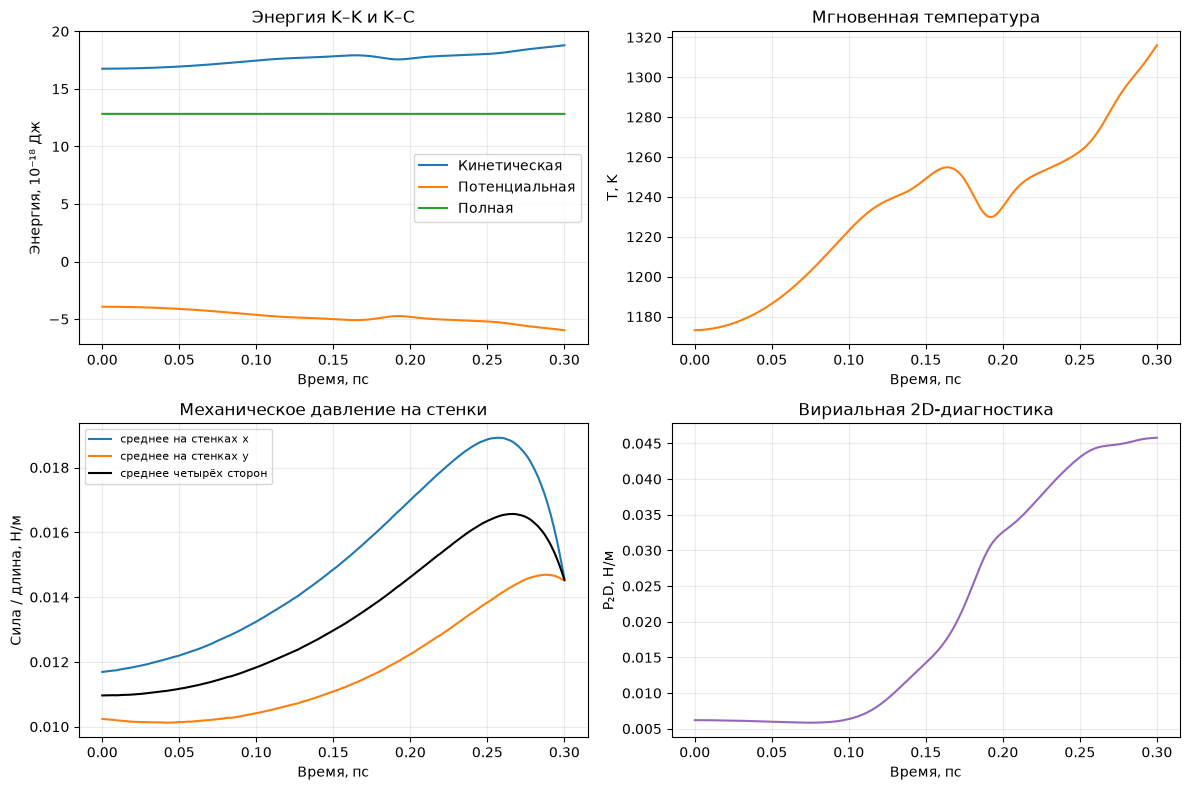

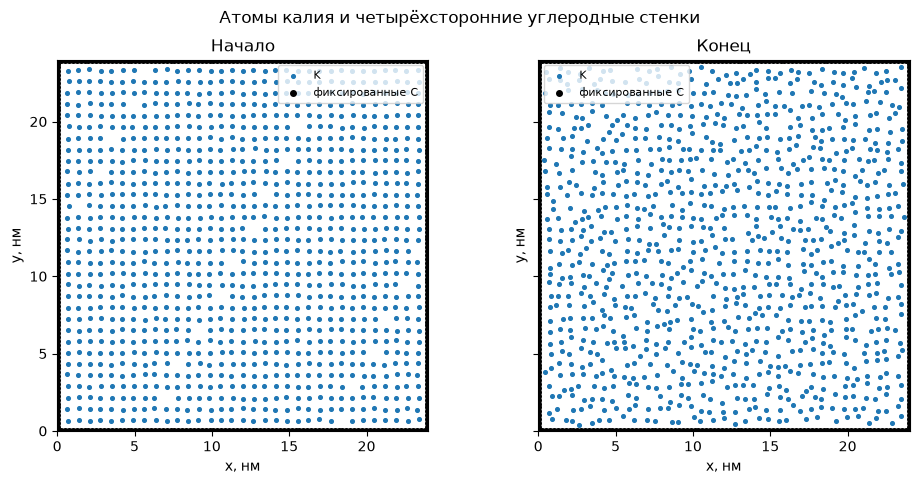

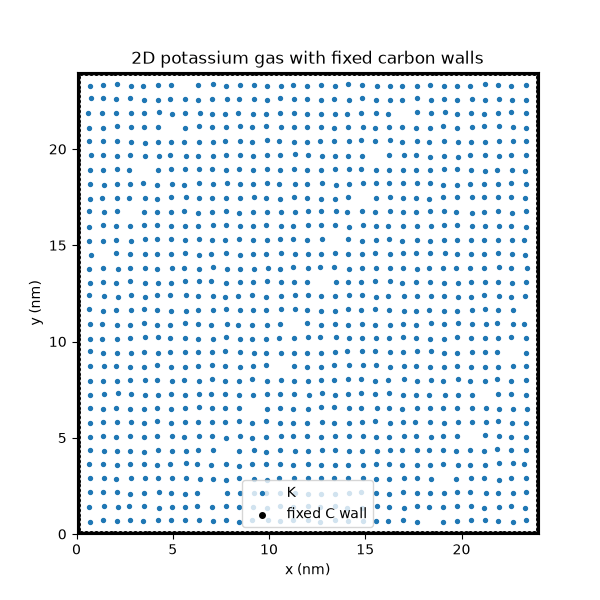

Данные и GIF сохранены в output/notebooks/task3_walls


In [3]:
time_ps = history['time'] * 1e12
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for key, label in [('kinetic_energy', 'Кинетическая'), ('potential_energy', 'Потенциальная'), ('total_energy', 'Полная')]:
    axes[0, 0].plot(time_ps, history[key] * 1e18, label=label)
axes[0, 0].set(title='Энергия K–K и K–C', xlabel='Время, пс', ylabel='Энергия, 10⁻¹⁸ Дж'); axes[0, 0].legend()
axes[0, 1].plot(time_ps, history['temperature'], color='tab:orange')
axes[0, 1].set(title='Мгновенная температура', xlabel='Время, пс', ylabel='T, K')
axes[1, 0].plot(time_ps, history['pressure_wall_x'], label='среднее на стенках x')
axes[1, 0].plot(time_ps, history['pressure_wall_y'], label='среднее на стенках y')
axes[1, 0].plot(time_ps, history['pressure_wall_mean'], color='black', linewidth=1.5, label='среднее четырёх сторон')
axes[1, 0].set(title='Механическое давление на стенки', xlabel='Время, пс', ylabel='Сила / длина, Н/м'); axes[1, 0].legend(fontsize=8)
axes[1, 1].plot(time_ps, history['pressure_2d'], color='tab:purple')
axes[1, 1].set(title='Вириальная 2D-диагностика', xlabel='Время, пс', ylabel='P₂D, Н/м')
for axis in axes.flat: axis.grid(alpha=0.25)
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharex=True, sharey=True)
for axis, frame, title in zip(axes, [frames[0], frames[-1]], ['Начало', 'Конец']):
    axis.scatter(frame[:, 0] * 1e9, frame[:, 1] * 1e9, s=7, label='K')
    axis.scatter(wall_positions[:, 0] * 1e9, wall_positions[:, 1] * 1e9, s=16, color='black', label='фиксированные C')
    axis.set(title=title, xlabel='x, нм', ylabel='y, нм', xlim=(0, config.box.lx * 1e9), ylim=(0, config.box.ly * 1e9), aspect='equal'); axis.legend(fontsize=8)
fig.suptitle('Атомы калия и четырёхсторонние углеродные стенки'); fig.tight_layout(); plt.show()

output_dir = PROJECT_ROOT / 'output' / 'notebooks' / 'task3_walls'
output_dir.mkdir(parents=True, exist_ok=True)
np.savetxt(output_dir / 'timeseries.csv', np.column_stack([history[key] for key in history]), delimiter=',', header=','.join(history), comments='')
gif_path = output_dir / 'trajectory.gif'
save_wall_animation(frames, wall_positions, config.box.lx, config.box.ly, gif_path)
display(Image(filename=str(gif_path)))
print(f'Данные и GIF сохранены в {output_dir.relative_to(PROJECT_ROOT)}')


### Интерпретация результатов

При приближении к углеродной стенке сила меняет компоненты скорости и отражается в колебаниях механического давления. Давление на x- и y-стенки может отличаться в короткой или неравновесной траектории; это не следует считать нарушением закона сохранения. В статическом консервативном поле стенок полная энергия подвижного газа плюс газ–стенка взаимодействие должна сохраняться с численной точностью интегратора, хотя кинетическая и потенциальная части обмениваются. Если стенка неподвижна, она может передать импульс частице, но сама не получает кинетическую энергию в данной модели.

Частицы не проникают сквозь стенки в корректно разрешённом режиме: очень крупный временной шаг или неудачная конфигурация могут привести к ошибке пересечения границы. Отсутствие колебаний на коротком DEMO-графике не является свидетельством равновесия. В реальном материале стенка вибрирует, имеет толщину и химическую/электронную структуру, которых здесь нет.

In [4]:
relative_drift = (history['total_energy'] - history['total_energy'][0]) / abs(history['total_energy'][0])
max_drift = float(np.max(np.abs(relative_drift)))
display(Markdown(f'**Рассчитанная сводка ({MODE}, seed {SEED}):** максимальный относительный дрейф полной энергии = {max_drift:.3e}; средняя температура = {np.mean(history["temperature"]):.2f} K; среднее механическое давление четырёх сторон = {np.mean(history["pressure_wall_mean"]):.4e} Н/м. Эти средние относятся только к длительности показанной траектории; равновесие отдельно не подтверждалось.'))


**Рассчитанная сводка (DEMO, seed 7):** максимальный относительный дрейф полной энергии = 1.621e-05; средняя температура = 1233.85 K; среднее механическое давление четырёх сторон = 1.3377e-02 Н/м. Эти средние относятся только к длительности показанной траектории; равновесие отдельно не подтверждалось.

## Возможные вопросы преподавателя

1. **Чем стенки отличаются от PBC?** PBC связывают противоположные края копиями области; стенки создают внешнее поле из фиксированных атомов.
2. **Почему атомы C неподвижны?** Это упрощённая модель твёрдой границы; она исключает вибрации и обратное движение материала стенки.
3. **Как вычислены K–C параметры?** Правилами Lorentz–Berthelot: среднее арифметическое для $\sigma$, среднее геометрическое для $\varepsilon$.
4. **Что такое UFF $x_C$?** Положение минимума для типа углерода в UFF; для стандартного LJ его переводят в $\sigma=x_C/2^{1/6}$.
5. **Что значит `engine.step()`?** Один шаг Velocity Verlet меняет координаты и скорости газа и возвращает словарь наблюдений.
6. **Что содержится в `wall_reaction`?** Силы, действующие со стороны газа на каждый закреплённый атом стенки.
7. **Как получено механическое давление?** Суммарную нормальную силу на сторону делим на длину этой стороны.
8. **Почему температура меняется?** Расчёт NVE не поддерживает её термостатом; скорость частиц обменивается энергией с потенциальным взаимодействием.
9. **Сохраняется ли энергия при фиксированной стенке?** Да, если газ взаимодействует с неизменным консервативным потенциалом и интегрируется достаточно малым шагом; внешнее поле не зависит явно от времени.
10. **Каковы ограничения?** 2D геометрия, один атомный ряд, неподвижная стенка, парный LJ и упрощённые параметры вместо динамического/электронного описания материала.